# 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import MissingIndicator
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (roc_auc_score, precision_score, recall_score, f1_score, roc_curve, confusion_matrix)
SEED = 591
pd.set_option("display.max_columns", 100)
pd.set_option("display.precision", 4)
print("Ready!")

Ready!


# 2. Load the Data and First Examination

In [2]:
df_raw = pd.read_csv('loan_default_project.csv')
df = df_raw.copy()
print("Shape:", df.shape)
df.head()

Shape: (316972, 37)


,ID,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,title,dti,earliest_cr_line,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,address,delinq_2yrs,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,last_credit_pull_d,acc_now_delinq,hardship_flag,debt_settlement_flag
0,60943837,15175.0,36 months,16.55,537.64,D,D2,Maintenance,9 years,MORTGAGE,33000.0,Source Verified,Oct-2015,Fully Paid,debt_consolidation,Debt consolidation,23.56,Sep-2006,11.0,0.0,11376.0,46.1,24.0,f,INDIVIDUAL,2.0,0.0,"359 Miles Neck\r\nEast Fernando, ME 22690",4.0,680.0,684.0,1.0,5.0,Apr-2018,0.0,N,N
1,8955171,7500.0,36 months,11.99,249.08,B,B3,Professional,6 years,RENT,40000.0,Not Verified,Dec-2013,Charged Off,credit_card,Credit Fund,29.49,Sep-2002,11.0,0.0,7113.0,56.5,23.0,w,INDIVIDUAL,0.0,0.0,"630 James Corners\r\nNew Frederick, NV 93700",0.0,680.0,684.0,0.0,43.0,Oct-2016,0.0,N,N
2,10171435,12000.0,60 months,24.50,348.71,F,F3,Purchasing,4 years,MORTGAGE,70000.0,Source Verified,Jan-2014,Charged Off,debt_consolidation,Credit,18.50,Feb-1997,12.0,0.0,11699.0,83.6,48.0,w,INDIVIDUAL,6.0,0.0,"2082 Williams Green Apt. 298\r\nWest Ashley, W...",0.0,665.0,669.0,3.0,69.0,Feb-2017,0.0,N,N
3,8658237,10300.0,36 months,12.99,347.00,B,B4,Loan Compliance,10+ years,MORTGAGE,35000.0,Verified,Nov-2013,Charged Off,debt_consolidation,high interest relief,11.15,Aug-1996,11.0,0.0,1907.0,23.8,37.0,f,INDIVIDUAL,5.0,0.0,"78651 Sampson Motorway Suite 078\r\nChangfort,...",0.0,705.0,709.0,0.0,38.0,Mar-2019,0.0,N,N
4,6533627,12000.0,36 months,13.05,404.62,B,B5,Wells Fargo,2 years,RENT,85000.0,Verified,Aug-2013,Fully Paid,debt_consolidation,Credit Card Payoff,33.36,May-1994,21.0,0.0,21133.0,58.7,35.0,f,INDIVIDUAL,2.0,0.0,"375 Quinn Gateway Suite 800\r\nPort Cesarview,...",1.0,665.0,669.0,0.0,20.0,May-2017,0.0,N,N


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 316972 entries, 0 to 316971
Data columns (total 37 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   ID                      316972 non-null  int64  
 1   loan_amnt               316972 non-null  float64
 2   term                    316972 non-null  str    
 3   int_rate                316972 non-null  float64
 4   installment             316972 non-null  float64
 5   grade                   316972 non-null  str    
 6   sub_grade               316972 non-null  str    
 7   emp_title               298521 non-null  str    
 8   emp_length              302316 non-null  str    
 9   home_ownership          316972 non-null  str    
 10  annual_inc              316972 non-null  float64
 11  verification_status     316972 non-null  str    
 12  issue_d                 316972 non-null  str    
 13  loan_status             316972 non-null  str    
 14  purpose                 316972 



**Things to notice:**
- Several columns that should be numbers or dates are stored as text (`object`): `term` (`" 36 months"`), `emp_length` (`"10+ years"`), `issue_d` and `earliest_cr_line` (`"Oct-2015"`). These are fixed in Section 3.
- Non-null counts below the row total mean missing values (for example, `mths_since_last_delinq`, `mort_acc`, `emp_title`, `emp_length`). These are handled in Section 6.

loan_status
Fully Paid     254793
Charged Off     62179
Name: count, dtype: int64

loan_status
Fully Paid     0.8038
Charged Off    0.1962
Name: proportion, dtype: float64


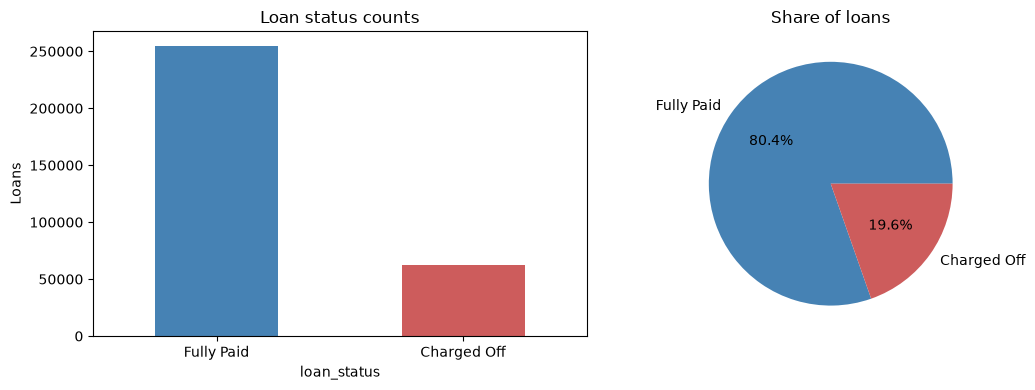

In [4]:
df["default"] = (df["loan_status"] == "Charged Off").astype(int)

print(df["loan_status"].value_counts())
print()
print(df["loan_status"].value_counts(normalize=True).round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["loan_status"].value_counts().plot(kind="bar", ax=ax[0], color=["steelblue", "indianred"])
ax[0].set_title("Loan status counts"); ax[0].set_ylabel("Loans"); ax[0].tick_params(axis="x", rotation=0)
df["loan_status"].value_counts().plot(kind="pie", ax=ax[1], autopct="%1.1f%%",
                                      colors=["steelblue", "indianred"], ylabel="")
ax[1].set_title("Share of loans")
plt.tight_layout(); plt.show()



**Result:** about **19.6%** of loans charged off vs **80.4%** paid in full, a roughly 4:1 **class imbalance**.



# 3. Variable Roles, Data Types, and Leakage

In [5]:
print("Unique IDs:", df["ID"].nunique(), "of", len(df), "rows")
print("Rows sharing an ID with another row:", df["ID"].duplicated(keep=False).sum())

## Are rows with the same ID actually the same loan?
display(df[df["ID"].duplicated(keep=False)].sort_values("ID")
        [["ID", "loan_amnt", "int_rate", "issue_d", "annual_inc", "loan_status"]].head(6))

## True duplicates = identical in every column except ID
dup_mask = df.drop(columns="ID").duplicated()
print("Exact duplicate rows (ignoring ID):", dup_mask.sum())

Unique IDs: 311785 of 316972 rows
Rows sharing an ID with another row: 10303


,ID,loan_amnt,int_rate,issue_d,annual_inc,loan_status
133220,138582,3275.0,9.33,Oct-2007,62000.0,Fully Paid
122554,138582,8275.0,9.01,Oct-2007,120000.0,Fully Paid
196115,347611,7500.0,9.76,May-2008,38168.0,Fully Paid
313129,347611,7500.0,12.29,May-2008,500000.0,Fully Paid
134950,350345,7500.0,8.00,Jun-2008,48000.0,Fully Paid
62415,350345,7500.0,11.66,Jun-2008,61000.0,Fully Paid


Exact duplicate rows (ignoring ID): 87



- About 5,000 IDs are **reused by different loans**. The example rows show the same ID with different amounts, rates and incomes. So `ID` isn't a reliable key, and it says nothing about default risk → **drop it**.
- **87 rows** are exact duplicates of another row in every column except ID → **remove them**.

In [6]:
df = df.loc[~dup_mask].drop(columns="ID").reset_index(drop=True)
print("Shape after removing duplicates and ID:", df.shape)

Shape after removing duplicates and ID: (316885, 37)


In [7]:
print(pd.crosstab(df["debt_settlement_flag"], df["loan_status"]))
print()
print("hardship_flag levels:", df["hardship_flag"].unique())
print()
## last_credit_pull_d: the latest date LendingClub pulled the borrower's credit (often after the loan ended)
print(pd.crosstab(df["last_credit_pull_d"].str[-4:], df["loan_status"], normalize="index").round(3).tail(5))

loan_status           Charged Off  Fully Paid
debt_settlement_flag                         
N                           58002      254708
Y                            4175           0

hardship_flag levels: <StringArray>
['N']
Length: 1, dtype: str

loan_status         Charged Off  Fully Paid
last_credit_pull_d                         
2015                      0.038       0.962
2016                      0.429       0.571
2017                      0.322       0.678
2018                      0.135       0.865
2019                      0.074       0.926



**Results:**
- **`debt_settlement_flag`:** every loan with `Y` (about 4,200) charged off, and not one was paid in full. People only enter debt settlement *after* defaulting, so this is **data leakage**.
- **`hardship_flag`:** only one value (`N`), so it carries **no information**.
- **`last_credit_pull_d`:** the default rate swings wildly by year (about 43% in 2016 vs about 7% in 2019). This date is recorded *after* the loan was funded, so it's leakage too.

 A predictor must be known **on the day someone applies**. Anything recorded later makes the model look better than it really is.

In [8]:
df = df.drop(columns=["debt_settlement_flag", "last_credit_pull_d", "hardship_flag"])

**What this does:** drops the two leakage columns and the constant column identified above.

The other extra columns (`delinq_2yrs`, `fico_range_low/high`, `inq_last_6mths`, `mths_since_last_delinq`, `acc_now_delinq`) describe the borrower's credit file **at application**, so they're legitimate predictors and are kept.

In [9]:
df["term"] = df["term"].str.extract(r"(\d+)")[0].astype(int)

df["emp_length"] = (df["emp_length"]
                    .replace({"< 1 year": "0 years"})
                    .str.extract(r"(\d+)")[0]
                    .astype(float))

df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y")
df["earliest_cr_line"] = pd.to_datetime(df["earliest_cr_line"], format="%b-%Y")

df["zip_code"] = df["address"].str[-5:]
df["addr_state"] = df["address"].str.extract(r"\s([A-Z]{2})\s\d{5}$")[0]

display(df[["term", "emp_length", "issue_d", "earliest_cr_line", "zip_code", "addr_state"]].head())
print(df[["term", "emp_length", "issue_d", "earliest_cr_line"]].dtypes)

,term,emp_length,issue_d,earliest_cr_line,zip_code,addr_state
0,36,9.0,2015-10-01,2006-09-01,22690,ME
1,36,6.0,2013-12-01,2002-09-01,93700,NV
2,60,4.0,2014-01-01,1997-02-01,30723,WI
3,36,10.0,2013-11-01,1996-08-01,86630,CT
4,36,2.0,2013-08-01,1994-05-01,22690,SD


term                         int64
emp_length                 float64
issue_d             datetime64[us]
earliest_cr_line    datetime64[us]
dtype: object


fixes data types and creates two variables from `address`:
- `term`: `" 36 months"` → `36` (number)
- `emp_length`: `"< 1 year"` → 0, `"10+ years"` → 10, matching the variable description (0–10)
- `issue_d`, `earliest_cr_line`: text → real dates, so we can compute credit-history length later
- `zip_code`: last 5 characters of the address
- `addr_state`: the 2 capital letters before the zip (regex)



# 4. Summary Statistics and Frequency Tables

In [10]:
numeric_cols = df.select_dtypes(include="number").columns.drop("default")
categorical_cols = df.select_dtypes(include="object").columns.drop(["loan_status", "address"])

print("Numeric variables:", len(numeric_cols))
print("Categorical variables:", len(categorical_cols))

summary = df[numeric_cols].describe().T
summary["median"] = df[numeric_cols].median()
summary["skew"] = df[numeric_cols].skew()
summary.round(2)

Numeric variables: 20
Categorical variables: 11


/var/folders/cf/byxvfh7s70bbn8fk1cknp_0w0000gn/T/ipykernel_88859/740597473.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns.drop(["loan_status", "address"])


,count,mean,std,min,25%,50%,75%,max,median,skew
loan_amnt,316885.0,14111.12,8355.17,500.00,8000.00,12000.00,20000.00,4.0000e+04,12000.00,0.78
term,316885.0,41.68,10.20,36.00,36.00,36.00,36.00,6.0000e+01,36.00,1.24
int_rate,316885.0,13.63,4.47,5.32,10.38,13.33,16.49,3.0990e+01,13.33,0.42
installment,316885.0,431.79,250.62,16.08,250.33,375.43,567.41,1.5338e+03,375.43,0.98
emp_length,302229.0,5.94,3.64,0.00,3.00,6.00,10.00,1.0000e+01,6.00,-0.21
annual_inc,316885.0,74235.85,62518.87,0.00,45000.00,64000.00,90000.00,8.7066e+06,64000.00,41.69
dti,316885.0,17.38,19.52,0.00,11.28,16.90,22.98,9.9990e+03,16.90,421.82
open_acc,316885.0,11.32,5.14,0.00,8.00,10.00,14.00,9.0000e+01,10.00,1.21
pub_rec,316885.0,0.18,0.54,0.00,0.00,0.00,0.00,8.6000e+01,0.00,18.78
revol_bal,316885.0,15817.27,20100.18,0.00,6024.00,11177.00,19601.00,1.2988e+06,11177.00,9.64



**What stands out:**
- `dti` has a max of **9,999**, an impossible debt-to-income value (placeholder or error).
- `annual_inc` runs from **$0 to $8.7 million** (median $64,000), so it's extremely right-skewed.
- `revol_util` reaches **892%**, while normal utilization is 0–~100%.
- Count variables (`pub_rec`, `delinq_2yrs`, `acc_now_delinq`) are mostly 0 with long tails (high skew).

These lead directly to the outlier decisions (Section 7) and the log transforms (later).

In [11]:
## Cardinality (number of levels) for each categorical variable
cardinality = df[categorical_cols].nunique().sort_values(ascending=False).to_frame("Unique levels")
cardinality

,Unique levels
emp_title,143505
title,40407
addr_state,54
sub_grade,35
purpose,14
zip_code,10
grade,7
home_ownership,6
verification_status,3
application_type,3



- `address` (~315k), `emp_title` (~143k) and `title` (~40k) are free text. Dummy-encoding them is impossible → group them or drop them.
- `sub_grade` (35) is an ordered version of `grade` (7) → convert it to a single number (A1 = 1 … G5 = 35).
- The date columns will become numeric features instead.

In [12]:
categorical_cols = df.select_dtypes(include=["object", "category"]).columns

for col in categorical_cols:
    table = (
        df[col]
        .value_counts(dropna=False)
        .rename_axis("Category")
        .reset_index(name="Frequency")
    )
    table["Percent"] = (table["Frequency"] / len(df) * 100).round(2)

    n_levels = df[col].nunique(dropna=False)
    print(f"\n{col}  ({n_levels} levels)")
    if n_levels > 50:
        print("High cardinality - showing top 10 only")
        display(table.head(10))
    else:
        display(table)


grade  (7 levels)


/var/folders/cf/byxvfh7s70bbn8fk1cknp_0w0000gn/T/ipykernel_88859/3632049369.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object", "category"]).columns


,Category,Frequency,Percent
0,B,92806,29.29
1,C,84909,26.79
2,A,51566,16.27
3,D,50680,15.99
4,E,25155,7.94
5,F,9367,2.96
6,G,2402,0.76



sub_grade  (35 levels)


,Category,Frequency,Percent
0,B3,21266,6.71
1,B4,20507,6.47
2,C1,18923,5.97
3,C2,18127,5.72
4,B2,17961,5.67
5,B5,17633,5.56
6,C3,16998,5.36
7,C4,16234,5.12
8,B1,15439,4.87
9,A5,14971,4.72



emp_title  (143506 levels)
High cardinality - showing top 10 only


... (18 outputs left out)


zip_code  (10 levels)


,Category,Frequency,Percent
0,70466,45602,14.39
1,30723,45352,14.31
2,22690,45323,14.30
3,48052,44637,14.09
4,00813,36590,11.55
5,29597,36469,11.51
6,05113,36318,11.46
7,11650,8955,2.83
8,93700,8930,2.82
9,86630,8709,2.75



addr_state  (54 levels)
High cardinality - showing top 10 only


,Category,Frequency,Percent
0,AP,11431,3.61
1,AE,11271,3.56
2,AA,11105,3.50
3,NV,5712,1.80
4,NJ,5688,1.79
5,MA,5672,1.79
6,WI,5666,1.79
7,LA,5654,1.78
8,SC,5653,1.78
9,TX,5650,1.78



**Things to notice:**
- `home_ownership`: `OTHER`, `NONE`, `ANY` add up to about 120 loans → group them into `OTHER`.
- `application_type`: 99.8% `INDIVIDUAL`.
- `purpose`: about 59% debt consolidation; `renewable_energy`, `educational` and `wedding` are each under 0.5% → group them into `other`.
- `emp_title`: thousands of one-off job titles → keep the top 15, plus `Other` and `Missing`.

# 5. Data Visualization


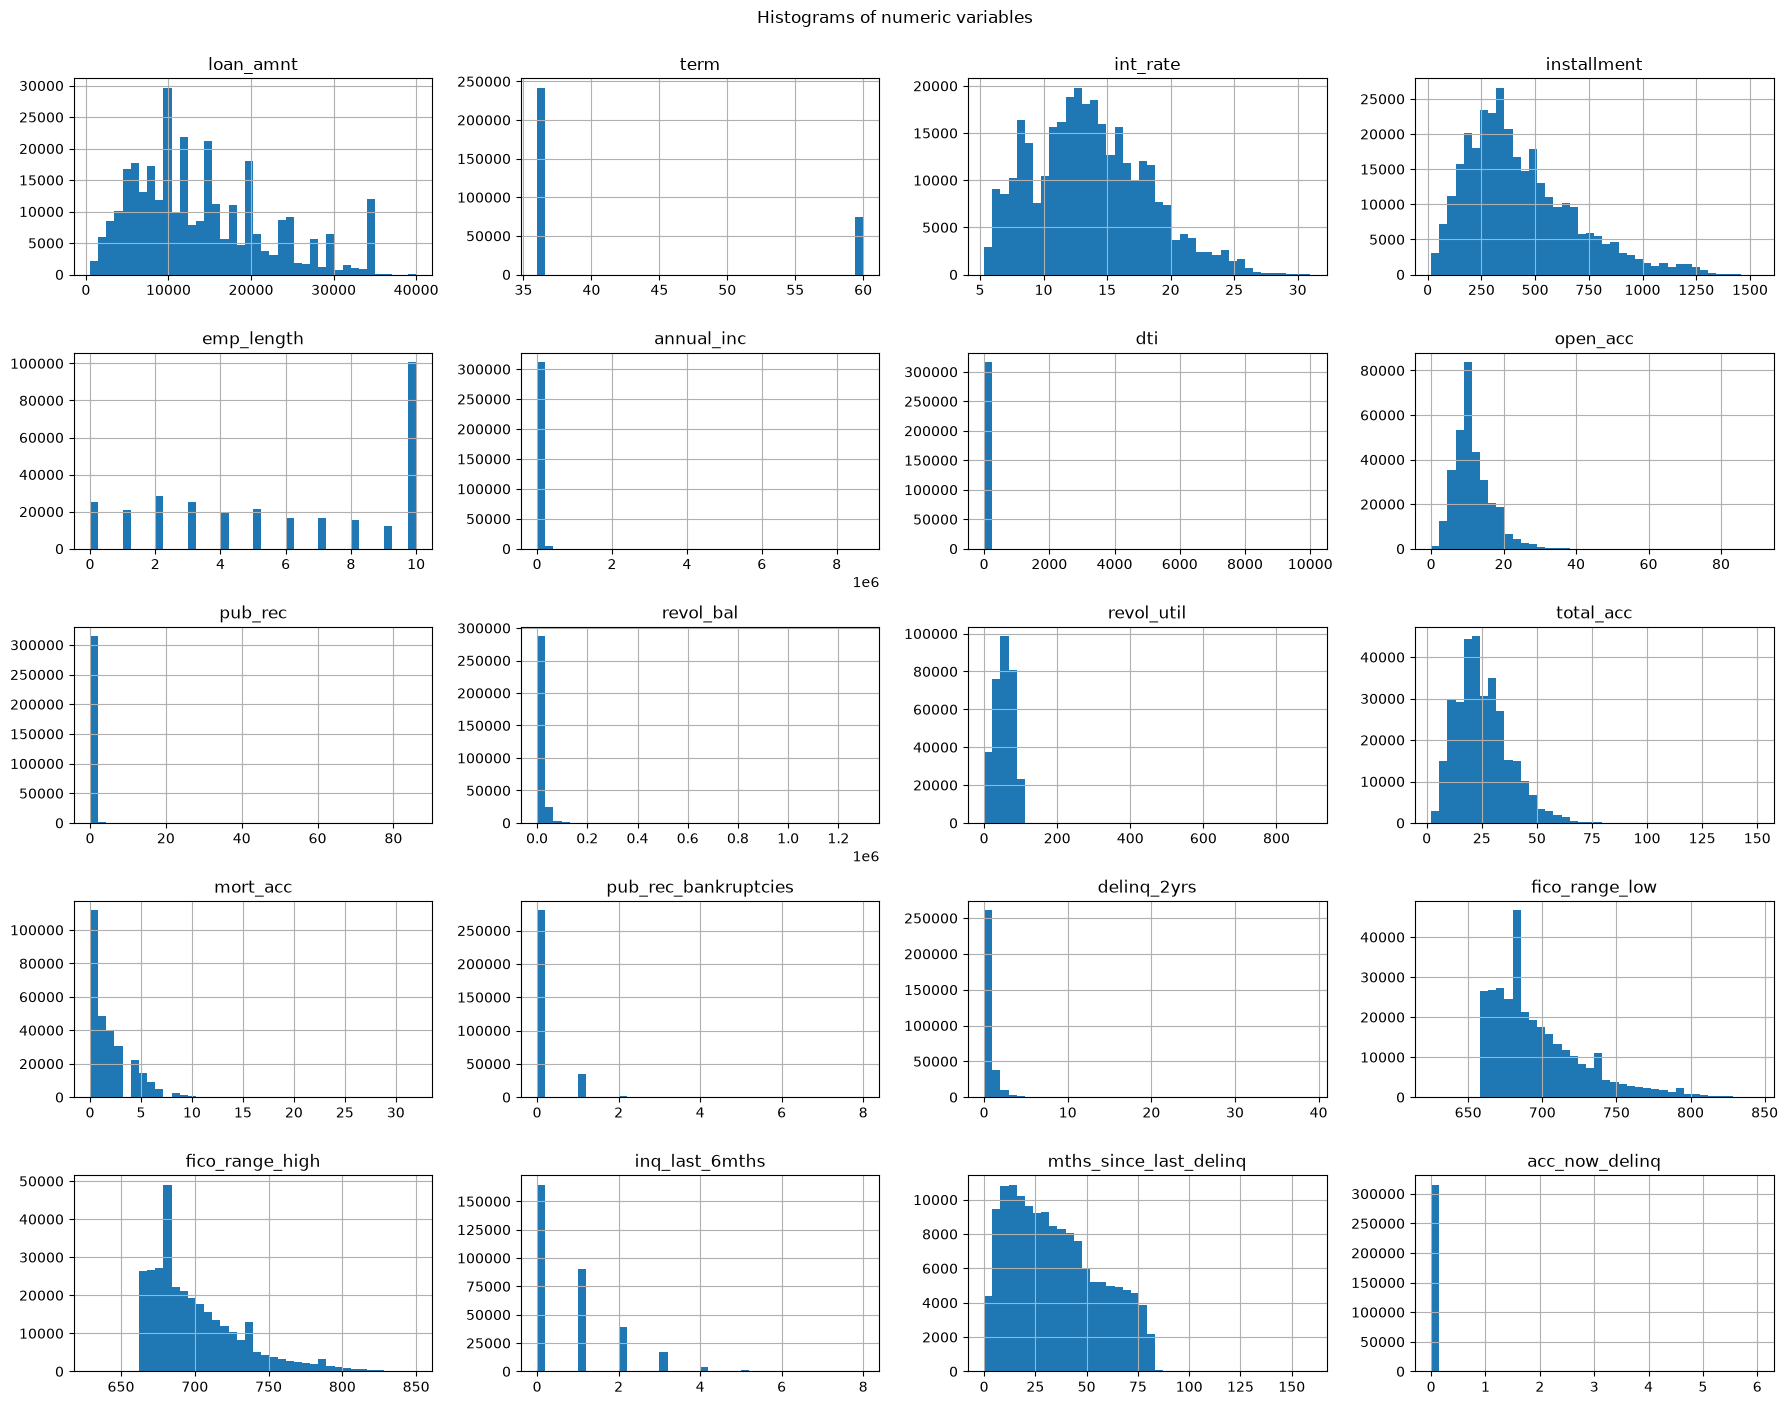

In [13]:
df[numeric_cols].hist(bins=40, figsize=(18, 14))
plt.suptitle("Histograms of numeric variables", y=1.0)
plt.tight_layout()
plt.show()


**Takeaways:** most money and count variables are **right-skewed** (`annual_inc`, `revol_bal`, `pub_rec`, `delinq_2yrs`). A few extreme values squash the rest of each histogram, which confirms the need for capping and log transforms. `int_rate`, `fico`, `dti` and `revol_util` look closer to normal.

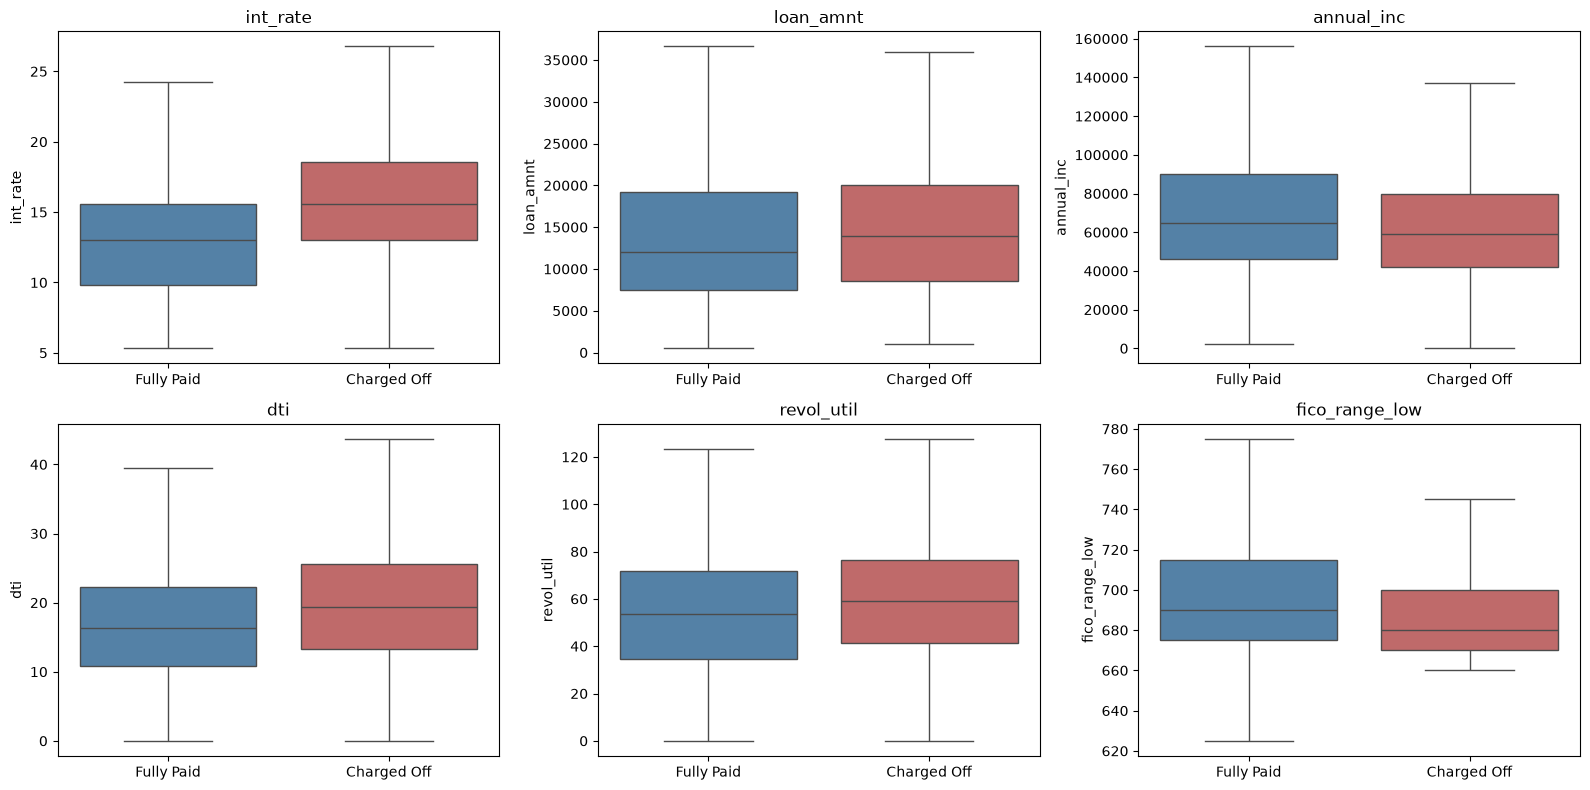

In [14]:
key_vars = ["int_rate", "loan_amnt", "annual_inc", "dti", "revol_util", "fico_range_low"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), key_vars):
    sns.boxplot(data=df, x="loan_status", y=col, ax=ax, showfliers=False,
                hue="loan_status", palette=["steelblue", "indianred"], legend=False)
    ax.set_title(col); ax.set_xlabel("")
plt.tight_layout()
plt.show()


**Takeaways:** charged-off loans have clearly **higher interest rates** and **lower FICO scores**, plus slightly higher loan amounts, DTI and revolving utilization, and slightly lower income. Interest rate is the strongest numeric signal, which makes sense: the lender already prices risk into the rate.

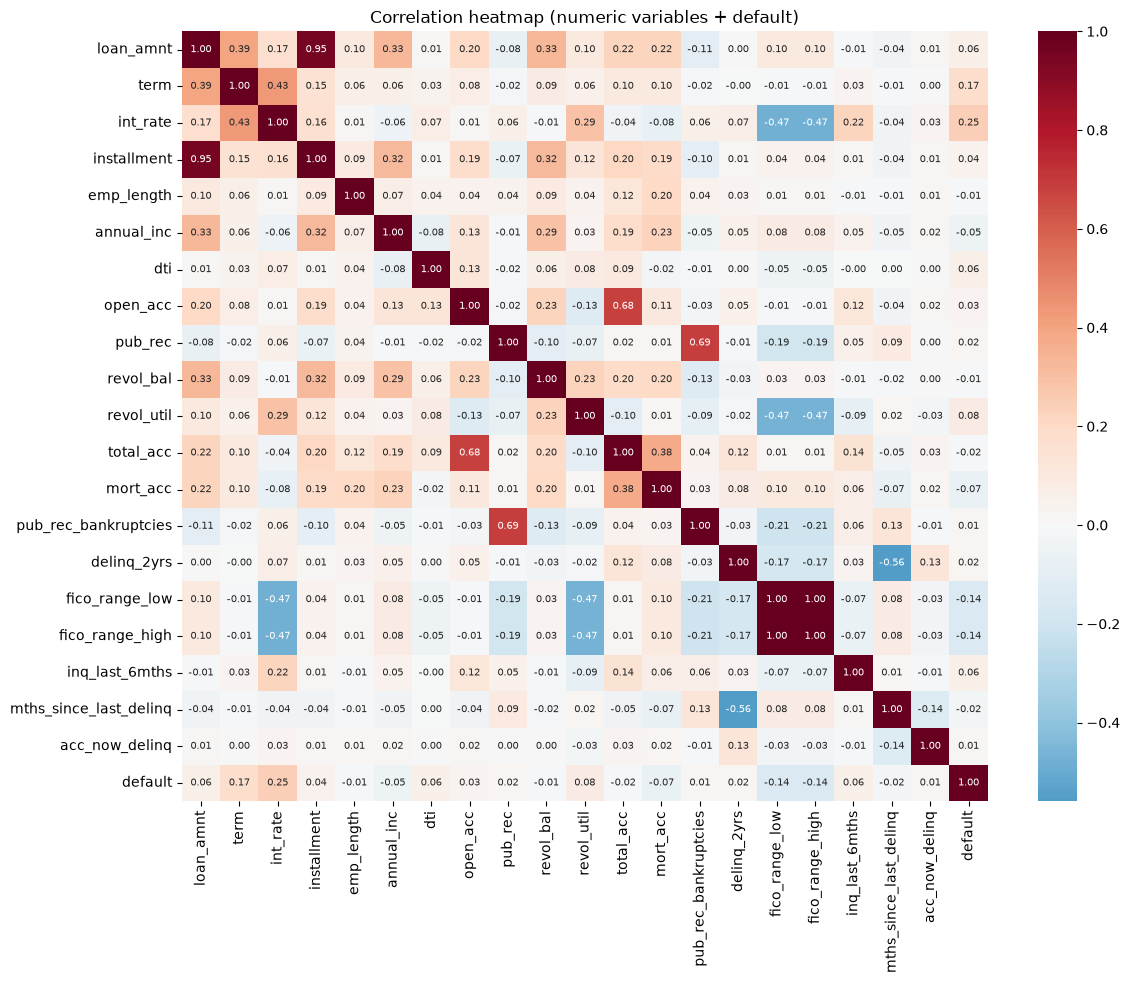

In [15]:
corr = df[list(numeric_cols) + ["default"]].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation heatmap (numeric variables + default)")
plt.show()

In [16]:
## Top 10 most correlated pairs of predictors (absolute value)
corr_matrix = df[numeric_cols].corr().abs()
stacked = corr_matrix.stack().sort_values(ascending=False)
most_correlated = stacked[stacked < 1].drop_duplicates().head(10)
print("Top 10 most correlated pairs (absolute value):")
display(most_correlated)

print("\nCorrelation of each numeric variable with default:")
display(corr["default"].drop("default").sort_values())

Top 10 most correlated pairs (absolute value):


fico_range_low          fico_range_high    1.0000
loan_amnt               installment        0.9539
pub_rec_bankruptcies    pub_rec            0.6929
total_acc               open_acc           0.6814
mths_since_last_delinq  delinq_2yrs        0.5594
fico_range_low          int_rate           0.4743
int_rate                fico_range_high    0.4743
revol_util              fico_range_low     0.4707
                        fico_range_high    0.4707
int_rate                term               0.4339
dtype: float64


Correlation of each numeric variable with default:


fico_range_low           -0.1411
fico_range_high          -0.1411
mort_acc                 -0.0712
annual_inc               -0.0523
mths_since_last_delinq   -0.0243
total_acc                -0.0168
emp_length               -0.0143
revol_bal                -0.0125
acc_now_delinq            0.0079
pub_rec_bankruptcies      0.0105
pub_rec                   0.0208
delinq_2yrs               0.0248
open_acc                  0.0277
installment               0.0412
dti                       0.0584
inq_last_6mths            0.0588
loan_amnt                 0.0601
revol_util                0.0830
term                      0.1736
int_rate                  0.2479
Name: default, dtype: float64

**Top correlated pairs (redundancy):**
- `fico_range_low` and `fico_range_high`: **r = 1.00** (high is always low + 4) → replace both with one `fico_avg`.
- `installment` and `loan_amnt`: **r = 0.95** (the payment is calculated from amount, rate and term) → drop `installment` and keep its information in an `installment_to_income` ratio.
- `pub_rec`/`pub_rec_bankruptcies` (0.69) and `open_acc`/`total_acc` (0.68) measure different things → keep both.

**Correlation with default:** `int_rate` (+0.25), `term` (+0.17) and FICO (−0.14) are the strongest. Everything else is weak on its own, which is why we'll create ratio and interaction features.

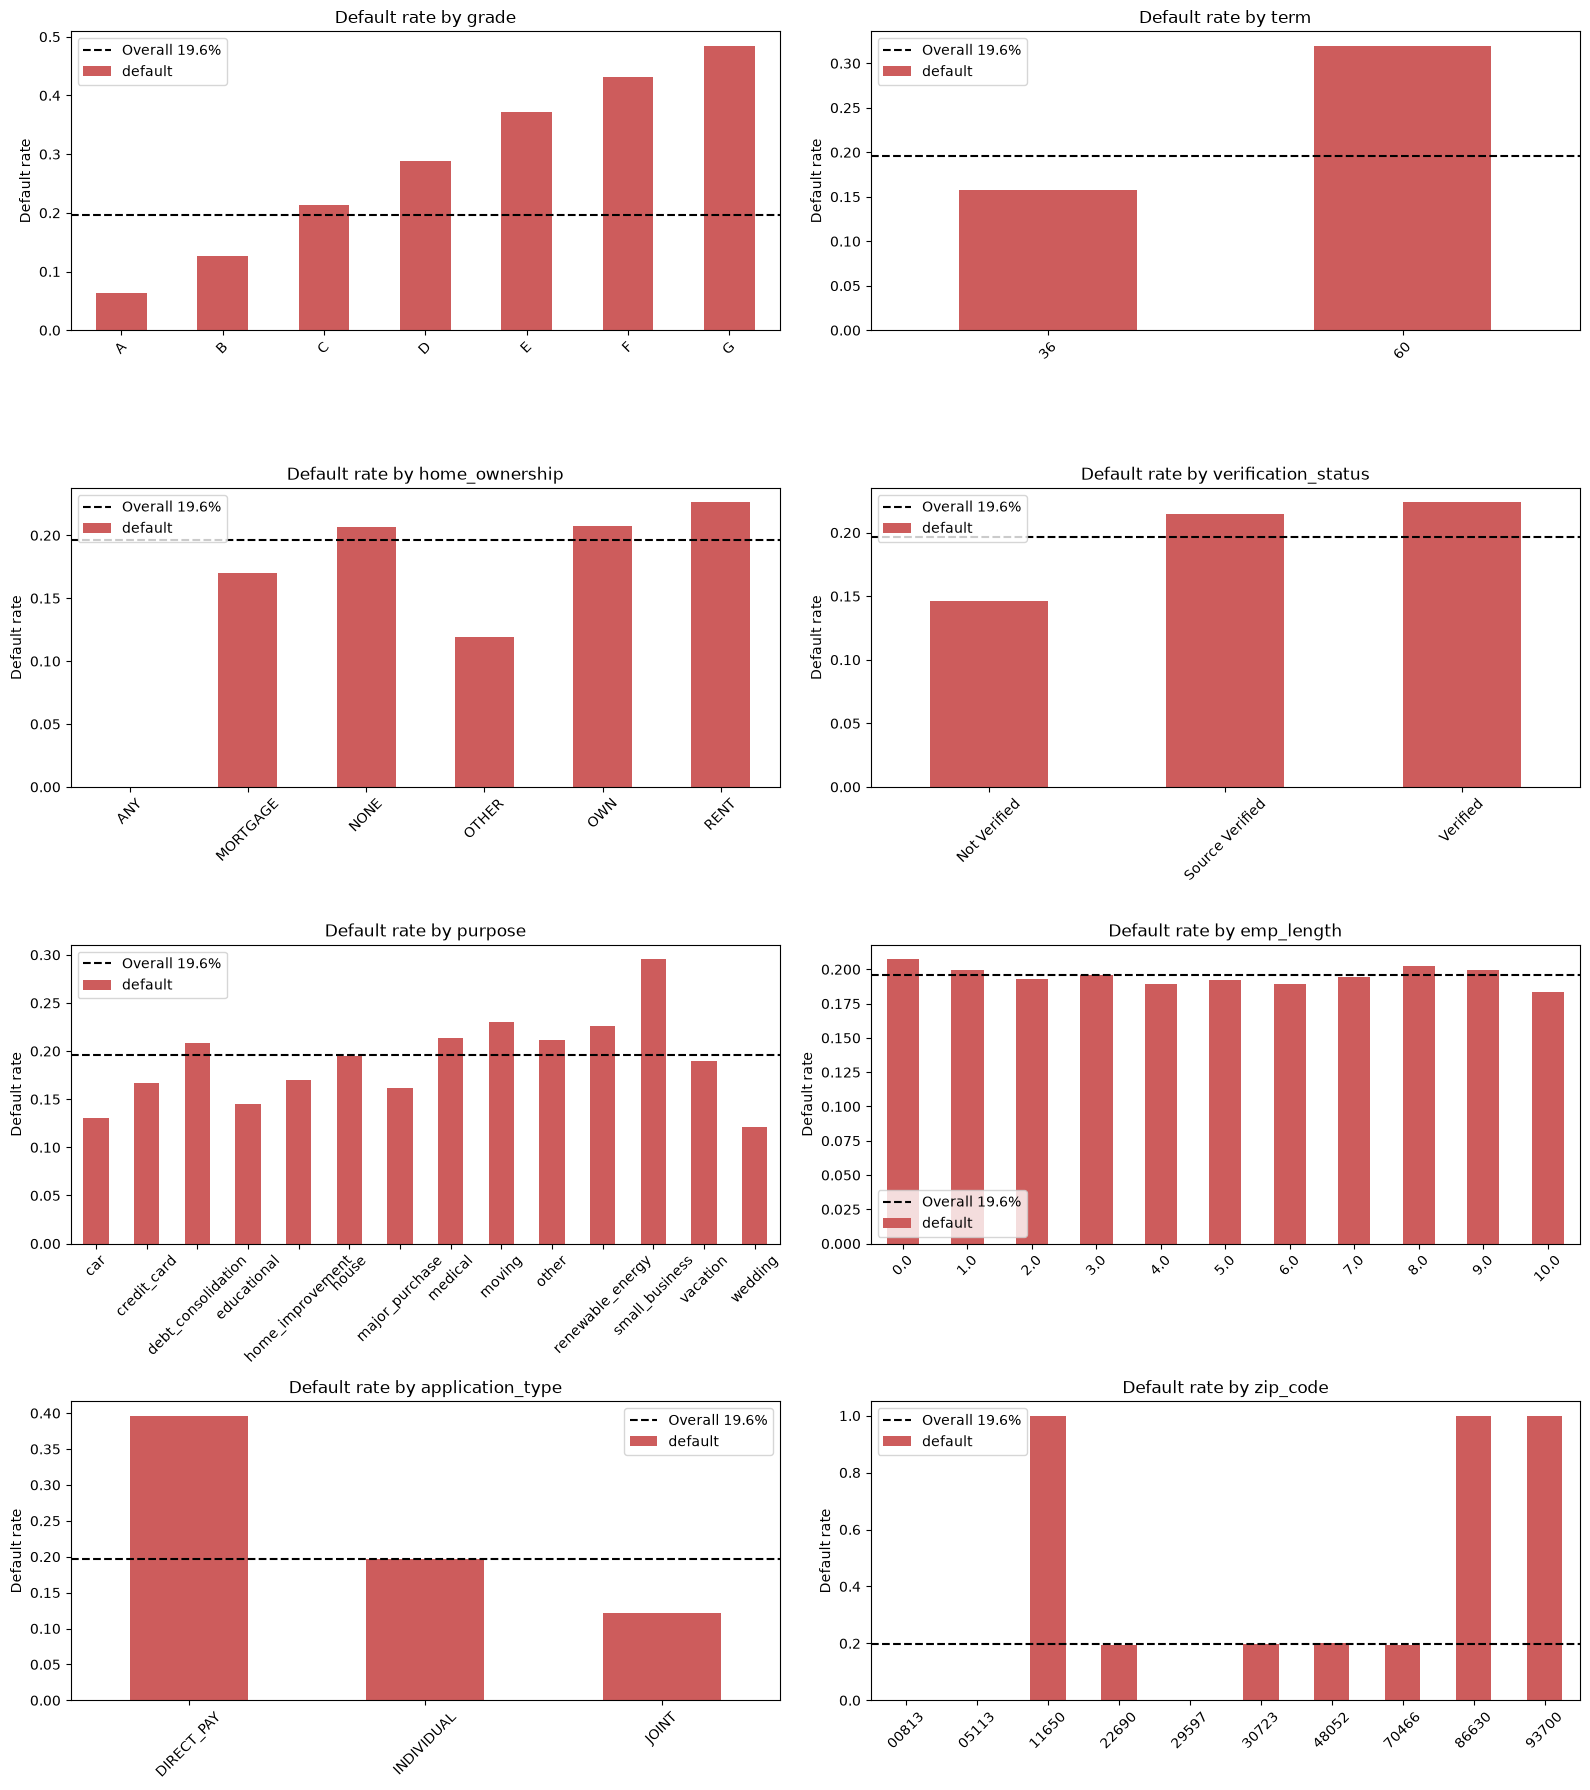

In [17]:
cat_plot_vars = ["grade", "term", "home_ownership", "verification_status",
                 "purpose", "emp_length", "application_type", "zip_code"]
overall_rate = df["default"].mean()

fig, axes = plt.subplots(4, 2, figsize=(16, 18))
for ax, col in zip(axes.ravel(), cat_plot_vars):
    rates = df.groupby(col)["default"].mean().sort_index()
    rates.plot(kind="bar", ax=ax, color="indianred")
    ax.axhline(overall_rate, color="black", linestyle="--", label=f"Overall {overall_rate:.1%}")
    ax.set_title(f"Default rate by {col}"); ax.set_ylabel("Default rate"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45); ax.legend()
plt.tight_layout()
plt.show()


**Takeaways:**
- **Grade** climbs steadily, from about **6% (A) to 49% (G)**. It's a very strong predictor.
- **60-month loans** default about twice as often as 36-month loans (32% vs 16%).
- **Renters** default more than mortgage holders. **Verified income** loans default *more* (the lender verifies riskier applicants).
- **Small business** is the riskiest purpose (~30%); car and wedding loans are the safest.
- `emp_length` hardly matters (18–21% across all levels).
- `DIRECT_PAY` is about 40%, but it's only 227 loans.
- **Zip code** has bars at exactly 0% and 100% (see the next cell).

In [18]:
zip_table = pd.crosstab(df["zip_code"], df["loan_status"], margins=True)
zip_table["Default rate"] = (zip_table["Charged Off"] / zip_table["All"]).round(3)
zip_table

loan_status,Charged Off,Fully Paid,All,Default rate
zip_code,,,,
00813,0,36590,36590,0.000
05113,0,36318,36318,0.000
11650,8955,0,8955,1.000
22690,8813,36510,45323,0.194
29597,0,36469,36469,0.000
30723,8902,36450,45352,0.196
48052,8972,35665,44637,0.201
70466,8896,36706,45602,0.195
86630,8709,0,8709,1.000


- 3 zip codes are **100% Charged Off** (about 8% of loans).
- 3 zip codes are **100% Fully Paid** (about 35% of loans).
- The other 4 sit right at the overall rate (~20%).

Real zip codes never separate defaults this cleanly, so the next cell checks whether these zip codes behave like real locations.

In [19]:
## Do these zip codes behave like real locations?
zip_check = df.groupby("zip_code").agg(Loans=("default", "size"),
                                       Default_rate=("default", "mean"),
                                       States=("addr_state", "nunique"),
                                       Avg_int_rate=("int_rate", "mean"),
                                       Median_income=("annual_inc", "median"))
zip_check.sort_values("Default_rate").round(3)

,Loans,Default_rate,States,Avg_int_rate,Median_income
zip_code,,,,,
00813,36590,0.000,54,13.072,65000.0
05113,36318,0.000,54,13.057,65000.0
29597,36469,0.000,54,13.105,65000.0
22690,45323,0.194,54,13.617,64000.0
70466,45602,0.195,54,13.642,64000.0
30723,45352,0.196,54,13.635,64000.0
48052,44637,0.201,54,13.641,64400.0
11650,8955,1.000,54,15.877,59000.0
86630,8709,1.000,54,15.889,58000.0


**Results:**
- **Every zip code appears in all 54 states.** A real zip code belongs to one place, so these zip codes have nothing to do with where borrowers actually live. The street addresses are made up.
- **Only 10 zip codes cover ~317,000 loans nationwide.** Real data would have hundreds of 3-digit prefixes.
- **Default rates of exactly 0% and 100%.** Even in real high-risk areas, most borrowers pay. A real location effect would look like 15% vs 25%, not a perfect split.
- The 100%-default zips do have higher rates and lower incomes, but only because they're filled with defaulters, and defaulters look like that on average. The zip isn't causing anything.

**Decision: drop `zip_code`.** In real lending, location *can* matter (local jobs, incomes, home prices), although fair-lending rules limit how lenders use it. But in this dataset the zip codes were evidently assigned based on the outcome itself, so it works like an answer key leaking into the features. Keeping it would let a model "predict" about 43% of loans perfectly (the six 0%/100% zips) and report test scores that would collapse on real applicants. In a test run with zip included, it took about 60% of the random forest's total importance.

**What this does:** a switch for the zip-code decision above. It's set to `False` because of the decision above, so `zip_code` is dropped. Setting it to `True` would put zip back in, for comparison only. It's used later, when we choose which columns to drop before encoding.

In [20]:
USE_ZIP = False   # zip_code is an artifact of how the data was generated (see above) -> dropped

In [21]:
## addr_state: is location by state informative?
state_rates = df.groupby("addr_state")["default"].agg(["mean", "size"]).sort_values("mean")
print("Number of states/territories:", len(state_rates))
print(state_rates["mean"].describe().round(3))

Number of states/territories: 54
count    54.000
mean      0.196
std       0.005
min       0.180
25%       0.193
50%       0.196
75%       0.199
max       0.210
Name: mean, dtype: float64


**What this shows:** the default rate in each state.

**Result:** 54 states/territories, and **every one sits between about 18% and 21%**, essentially the overall rate. State would add about 53 dummy columns with no signal → **drop `addr_state`** as uninformative.

# 6. Missing Data

,MissingCount,MissingFraction
mths_since_last_delinq,168727,0.5325
mort_acc,30350,0.0958
emp_title,18381,0.0580
emp_length,14656,0.0463
title,1431,0.0045
pub_rec_bankruptcies,432,0.0014
revol_util,221,0.0007


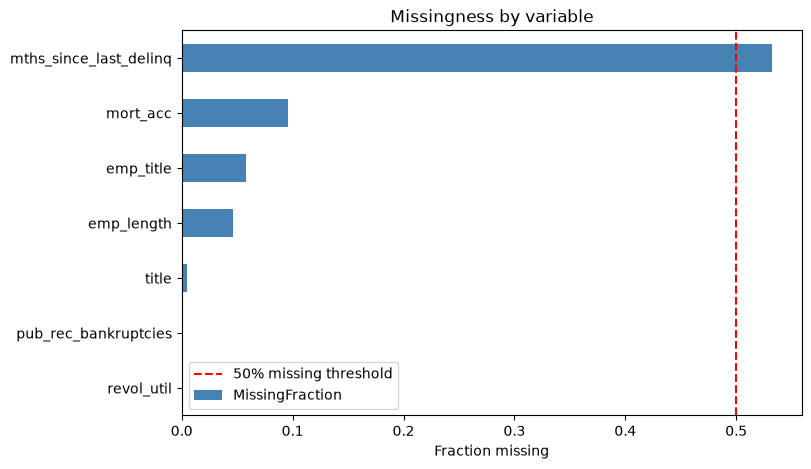

In [22]:
missing_table = pd.DataFrame({
    "MissingCount": df.isna().sum(),
    "MissingFraction": df.isna().mean()
})
missing_table = missing_table[missing_table["MissingCount"] > 0].sort_values("MissingFraction", ascending=False)
display(missing_table)

missing_table["MissingFraction"].sort_values().plot(kind="barh", figsize=(8, 5), color="steelblue")
plt.axvline(0.50, color="red", linestyle="--", label="50% missing threshold")
plt.xlabel("Fraction missing"); plt.title("Missingness by variable"); plt.legend()
plt.show()

In [23]:
rows = []
for col in missing_table.index:
    is_missing = df[col].isna()
    rows.append({"Variable": col,
                 "Default rate | missing": df.loc[is_missing, "default"].mean(),
                 "Default rate | present": df.loc[~is_missing, "default"].mean()})
pd.DataFrame(rows).set_index("Variable").round(3)

,Default rate | missing,Default rate | present
Variable,,
mths_since_last_delinq,0.190,0.203
mort_acc,0.146,0.201
emp_title,0.262,0.192
emp_length,0.278,0.192
title,0.179,0.196
pub_rec_bankruptcies,0.181,0.196
revol_util,0.222,0.196



**Results:**
- Missing `emp_title` or `emp_length` → about **26–28% default** vs 19% when present. Not reporting employment is a risk signal.
- Missing `mort_acc` → about 15% vs 20%.
- Missing `mths_since_last_delinq` → about 19% vs 20%.



# 7. Outliers and Impossible Values

In [24]:
## IQR rule: count potential outliers per numeric variable
num_check = df[numeric_cols]
Q1, Q3 = num_check.quantile(0.25), num_check.quantile(0.75)
IQR = Q3 - Q1
outlier_counts = ((num_check < Q1 - 1.5 * IQR) | (num_check > Q3 + 1.5 * IQR)).sum()
outlier_counts.sort_values(ascending=False).to_frame("IQR outliers").head(12)

,IQR outliers
term,75056
delinq_2yrs,55999
pub_rec,46177
pub_rec_bankruptcies,36057
inq_last_6mths,23192
revol_bal,17036
annual_inc,13329
fico_range_high,10826
fico_range_low,10826
installment,8968


/var/folders/cf/byxvfh7s70bbn8fk1cknp_0w0000gn/T/ipykernel_88859/2194597463.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  a.boxplot(df[col].dropna(), vert=False)
/var/folders/cf/byxvfh7s70bbn8fk1cknp_0w0000gn/T/ipykernel_88859/2194597463.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  a.boxplot(df[col].dropna(), vert=False)
/var/folders/cf/byxvfh7s70bbn8fk1cknp_0w0000gn/T/ipykernel_88859/2194597463.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  a.boxplot(df[col].dropna(), vert=False)


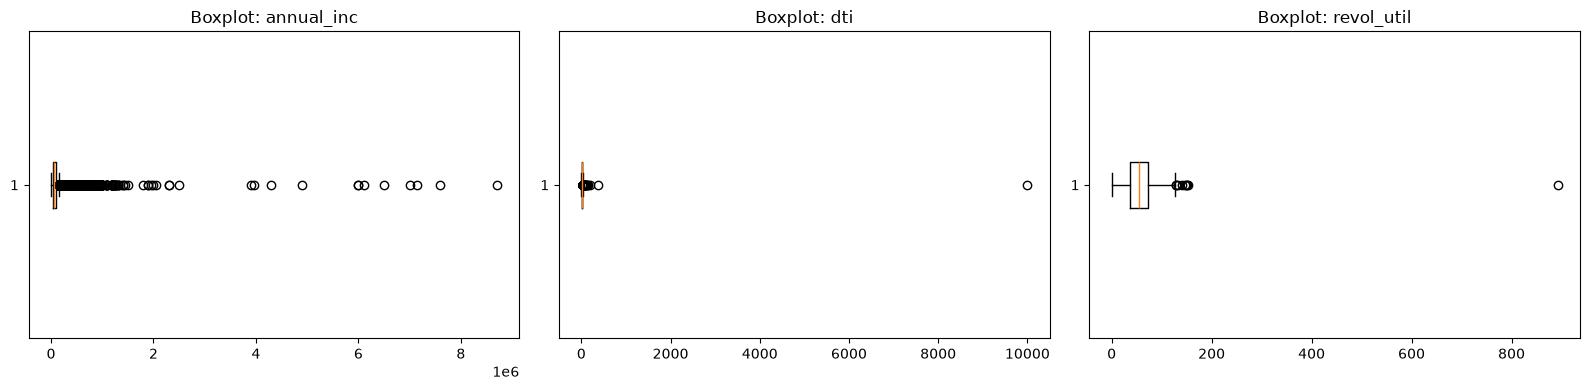

dti > 100: 6 -> [np.float64(120.66), np.float64(138.03), np.float64(145.65), np.float64(189.9), np.float64(380.53), np.float64(9999.0)]
annual_inc == 0: 1
revol_util > 150: 3 -> [np.float64(150.7), np.float64(153.0), np.float64(892.3)]
annual_inc 99th / 99.9th percentile: [250000.0, 525000.0]


In [25]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, ["annual_inc", "dti", "revol_util"]):
    a.boxplot(df[col].dropna(), vert=False)
    a.set_title(f"Boxplot: {col}")
plt.tight_layout(); plt.show()

print("dti > 100:", (df["dti"] > 100).sum(), "->", sorted(df.loc[df["dti"] > 100, "dti"].unique()))
print("annual_inc == 0:", (df["annual_inc"] == 0).sum())
print("revol_util > 150:", (df["revol_util"] > 150).sum(), "->", sorted(df.loc[df["revol_util"] > 150, "revol_util"].unique()))
print("annual_inc 99th / 99.9th percentile:", df["annual_inc"].quantile([0.99, 0.999]).tolist())


**Results and decisions:**
- `dti > 100`: 6 loans (e.g., **9,999**) → impossible → set to missing.
- `annual_inc == 0`: 1 loan → a $0 income can't produce a DTI → set to missing.
- `revol_util > 150`: 3 loans (e.g., **892%**) → set to missing.
- High incomes (99.9th percentile ≈ $525k) are **extreme but possible** → keep them, then cap at the training set's 99.9th percentile and log-transform later. We don't delete them.

In [26]:
df.loc[df["dti"] > 100, "dti"] = np.nan
df.loc[df["annual_inc"] == 0, "annual_inc"] = np.nan
df.loc[df["revol_util"] > 150, "revol_util"] = np.nan
print(df[["dti", "annual_inc", "revol_util"]].isna().sum())

dti             6
annual_inc      1
revol_util    224
dtype: int64


# 8. Feature Creation

In [27]:
## Ratio features: size of the loan, payment and revolving debt relative to income
df["loan_to_income"] = df["loan_amnt"] / df["annual_inc"]
df["installment_to_income"] = df["installment"] * 12 / df["annual_inc"]
df["revol_bal_to_income"] = df["revol_bal"] / df["annual_inc"]
df["open_acc_ratio"] = df["open_acc"] / df["total_acc"].replace(0, np.nan)

## Combined / converted features
df["fico_avg"] = (df["fico_range_low"] + df["fico_range_high"]) / 2
grade_order = [g + str(n) for g in "ABCDEFG" for n in range(1, 6)]
df["sub_grade_num"] = df["sub_grade"].map({sg: i + 1 for i, sg in enumerate(grade_order)})

## Time-based features
df["credit_hist_yrs"] = (df["issue_d"] - df["earliest_cr_line"]).dt.days / 365.25
df["issue_year"] = df["issue_d"].dt.year

## Interaction features
df["int_rate_x_term"] = df["int_rate"] * df["term"] / 12      # rough total interest % over the loan's life
df["loan_amnt_x_int_rate"] = df["loan_amnt"] * df["int_rate"] / 100   # first-year interest in dollars
df["dti_x_int_rate"] = df["dti"] * df["int_rate"]              # already stretched AND paying a high rate

## Binned and flag features
df["loan_size"] = pd.cut(df["loan_amnt"], bins=[0, 10000, 20000, np.inf],
                         labels=["small", "medium", "large"])
df["ever_delinq"] = df["mths_since_last_delinq"].notna().astype(int)

new_feats = ["loan_to_income", "installment_to_income", "revol_bal_to_income", "open_acc_ratio",
             "fico_avg", "sub_grade_num", "credit_hist_yrs", "issue_year",
             "int_rate_x_term", "loan_amnt_x_int_rate", "dti_x_int_rate", "ever_delinq"]
display(df[new_feats].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
loan_to_income,316884.0,0.21,0.11,0.00,0.13,0.20,0.29,7.35
installment_to_income,316884.0,0.08,0.04,0.00,0.05,0.07,0.11,2.65
revol_bal_to_income,316884.0,0.23,0.20,0.00,0.10,0.18,0.30,6.60
open_acc_ratio,316885.0,0.48,0.17,0.00,0.36,0.46,0.59,1.00
fico_avg,316885.0,698.57,31.64,627.00,672.00,692.00,712.00,847.50
sub_grade_num,316885.0,12.07,6.60,1.00,7.00,11.00,16.00,35.00
credit_hist_yrs,316885.0,15.75,7.20,3.00,10.92,14.34,19.33,70.16
issue_year,316885.0,2013.63,1.48,2007.00,2013.00,2014.00,2015.00,2016.00
int_rate_x_term,316885.0,48.99,25.12,15.96,32.25,41.94,57.66,154.95
loan_amnt_x_int_rate,316885.0,1986.08,1538.93,48.80,887.90,1536.00,2612.68,10996.00


**What this does:** builds 14 new features from the raw columns.
- **Ratios:** `loan_to_income`, `installment_to_income` (a year of payments ÷ income), `revol_bal_to_income` and `open_acc_ratio` (open ÷ total credit lines) measure how stretched the borrower is relative to what they earn.
- **Combined:** `fico_avg` replaces the two FICO columns (r = 1.00). `sub_grade_num` turns A1…G5 into 1…35 so the ordering is kept in one column, which makes `grade` and `sub_grade` unnecessary.
- **Time-based:** `credit_hist_yrs` is how long the borrower had credit when the loan was issued. `issue_year` captures the economic cohort. Issue *month* was checked and is flat (17–21% default every month), so it isn't used.
- **Interactions:** `int_rate_x_term`, `loan_amnt_x_int_rate` and `dti_x_int_rate` combine the strongest signals (rate, term, DTI) the way the assignment suggests.
- **Binned:** `loan_size` (small < $10k, medium $10–20k, large > $20k).
- **Flag:** `ever_delinq` = 1 if the borrower has any past delinquency. `mths_since_last_delinq` is 53% missing because most borrowers have *never* been delinquent, so the flag keeps that information and the raw column is dropped in Section 9.

Correlation of new numeric features with default:


fico_avg                -0.141
credit_hist_yrs         -0.027
ever_delinq              0.016
revol_bal_to_income      0.044
open_acc_ratio           0.059
issue_year               0.062
installment_to_income    0.128
loan_to_income           0.149
loan_amnt_x_int_rate     0.162
dti_x_int_rate           0.232
int_rate_x_term          0.251
sub_grade_num            0.263
Name: default, dtype: float64

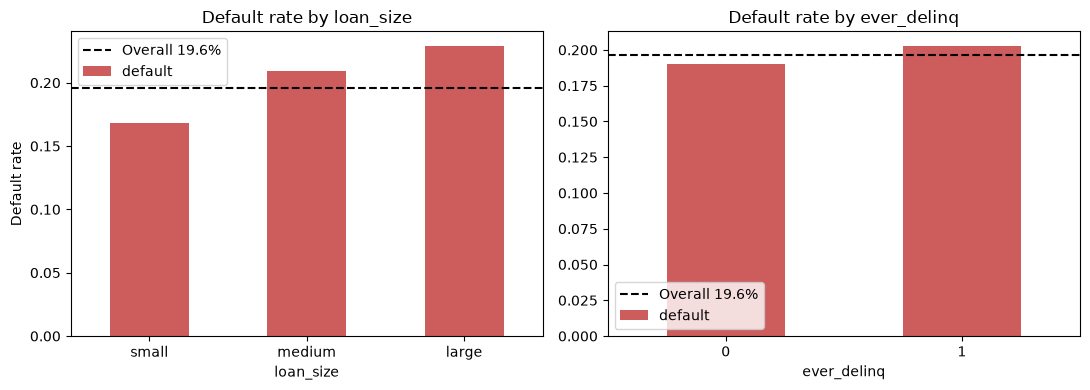

In [28]:
## Do the new features separate defaults from non-defaults?
print("Correlation of new numeric features with default:")
display(df[new_feats + ["default"]].corr()["default"].drop("default").sort_values().round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df.groupby("loan_size", observed=True)["default"].mean().plot(kind="bar", ax=ax[0], color="indianred")
ax[0].set_title("Default rate by loan_size"); ax[0].set_ylabel("Default rate"); ax[0].tick_params(axis="x", rotation=0)
df.groupby("ever_delinq")["default"].mean().plot(kind="bar", ax=ax[1], color="indianred")
ax[1].set_title("Default rate by ever_delinq"); ax[1].tick_params(axis="x", rotation=0)
for a in ax:
    a.axhline(overall_rate, color="black", linestyle="--", label=f"Overall {overall_rate:.1%}"); a.legend()
plt.tight_layout(); plt.show()

**Results:** `sub_grade_num` (+0.26), `int_rate_x_term` (+0.25) and `dti_x_int_rate` (+0.23) are the strongest new features, on par with `int_rate` by itself (+0.25). The income ratios `loan_to_income` (+0.15) and `installment_to_income` (+0.13) are much stronger than raw `annual_inc`. Default rises with loan size: 17% for small loans, 21% for medium and 23% for large. `ever_delinq` barely moves the rate (19% vs 20%).

# 9. Grouping Categories and Dropping Columns

In [29]:
## Rare levels -> grouped (decisions from Section 4)
df["home_ownership"] = df["home_ownership"].replace({"NONE": "OTHER", "ANY": "OTHER"})
df["purpose"] = df["purpose"].replace({"renewable_energy": "other", "educational": "other", "wedding": "other"})

## emp_title: clean the text, keep the 15 most common titles, everything else -> Other / Missing
titles = df["emp_title"].str.strip().str.lower().replace({"rn": "registered nurse"})
top15 = titles.value_counts().head(15).index
df["emp_title_grp"] = np.where(titles.isna(), "Missing",
                               np.where(titles.isin(top15), titles, "Other"))

print(df["home_ownership"].value_counts(), "\n")
print(df["purpose"].value_counts(), "\n")
emp_rates = df.groupby("emp_title_grp")["default"].agg(["mean", "size"]).sort_values("mean")
emp_rates.columns = ["Default rate", "Loans"]
emp_rates.round(3)

home_ownership
MORTGAGE    158633
RENT        127972
OWN          30157
OTHER          123
Name: count, dtype: int64 

purpose
debt_consolidation    187783
credit_card            66413
home_improvement       19200
other                  18779
major_purchase          7009
small_business          4572
car                     3791
medical                 3362
moving                  2270
vacation                1944
house                   1762
Name: count, dtype: int64 



,Default rate,Loans
emp_title_grp,,
vice president,0.131,846
director,0.160,993
police officer,0.164,880
engineer,0.173,981
project manager,0.177,1471
Other,0.188,268697
teacher,0.198,4460
registered nurse,0.206,3852
office manager,0.207,1380


**What this does:** carries out the grouping decisions from Section 4.
- `home_ownership`: `NONE` and `ANY` fold into `OTHER` (123 loans in total).
- `purpose`: `renewable_energy`, `educational` and `wedding` fold into `other`.
- `emp_title`: job titles are lowercased and trimmed first, so "Teacher" and "teacher " count as one title, and "rn" is merged into "registered nurse". The top 15 titles keep their own level. Everything else becomes `Other`, and blanks become `Missing`. That takes ~143,000 levels down to 17. The top-15 list comes from counts only (no target information), so building it before the split doesn't leak anything.

**Results:** job title carries real signal. Vice presidents and directors default 13–16% of the time, while owners, truck drivers and drivers default 29–33% of the time. Loans with no job title default at 26%, which matches Section 6.

In [30]:
drop_cols = ["loan_status",                          # replaced by the 0/1 target `default`
             "address", "addr_state",                # fake street text / uninformative (Section 5)
             "title", "emp_title",                   # free text, replaced by purpose / emp_title_grp
             "installment",                          # r = 0.95 with loan_amnt, kept as installment_to_income
             "fico_range_low", "fico_range_high",    # replaced by fico_avg
             "grade", "sub_grade",                   # replaced by sub_grade_num
             "issue_d", "earliest_cr_line",          # replaced by issue_year and credit_hist_yrs
             "mths_since_last_delinq"]               # 53% missing, replaced by ever_delinq
if not USE_ZIP:
    drop_cols.append("zip_code")

df = df.drop(columns=drop_cols)
print("Shape after dropping:", df.shape)
print(df.dtypes.value_counts())

Shape after dropping: (316885, 36)
float64     24
str          6
int64        4
int32        1
category     1
Name: count, dtype: int64


**What this does:** drops columns that are free text, uninformative, redundant, or have been replaced by an engineered feature. The comment on each line gives the reason. `zip_code` is dropped only if `USE_ZIP = False`.

# 10. Encoding Categorical Variables

In [31]:
cat_cols = ["home_ownership", "verification_status", "purpose", "initial_list_status",
            "application_type", "emp_title_grp", "loan_size"]
if USE_ZIP:
    cat_cols.append("zip_code")

df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

print("Shape after encoding:", df_encoded.shape)
print("Columns left as text:", df_encoded.select_dtypes(exclude="number").columns.tolist())
print("\nDummy columns created:")
print([c for c in df_encoded.columns if c not in df.columns])

Shape after encoding: (316885, 65)
Columns left as text: []

Dummy columns created:
['home_ownership_OTHER', 'home_ownership_OWN', 'home_ownership_RENT', 'verification_status_Source Verified', 'verification_status_Verified', 'purpose_credit_card', 'purpose_debt_consolidation', 'purpose_home_improvement', 'purpose_house', 'purpose_major_purchase', 'purpose_medical', 'purpose_moving', 'purpose_other', 'purpose_small_business', 'purpose_vacation', 'initial_list_status_w', 'application_type_INDIVIDUAL', 'application_type_JOINT', 'emp_title_grp_Other', 'emp_title_grp_director', 'emp_title_grp_driver', 'emp_title_grp_engineer', 'emp_title_grp_general manager', 'emp_title_grp_manager', 'emp_title_grp_office manager', 'emp_title_grp_owner', 'emp_title_grp_police officer', 'emp_title_grp_project manager', 'emp_title_grp_registered nurse', 'emp_title_grp_sales', 'emp_title_grp_supervisor', 'emp_title_grp_teacher', 'emp_title_grp_truck driver', 'emp_title_grp_vice president', 'loan_size_medium', 

**What this does:** one-hot (dummy) encodes every remaining categorical variable. `drop_first=True` leaves out one level per variable as the baseline, which avoids perfect multicollinearity in logistic regression; the dropped level is the one where all of that variable's dummies are 0. Ordered variables (`term`, `emp_length`, `sub_grade_num`) were already turned into numbers in Sections 3 and 8, so their order is kept rather than split into dummies.

Encoding happens before the split because it doesn't learn anything from the data (it just maps each level to a column), so it can't leak test information.

# 11. Train/Test Split

In [32]:
X = df_encoded.drop(columns="default")
y = df_encoded["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_test = X_train.copy(), X_test.copy()

print("X_train:", X_train.shape, "  X_test:", X_test.shape)
print(f"Default rate  train: {y_train.mean():.4f}   test: {y_test.mean():.4f}")

X_train: (253508, 64)   X_test: (63377, 64)
Default rate  train: 0.1962   test: 0.1962


**What this does:** splits the data 80% train / 20% test. With ~317,000 loans, 20% still gives ~63,000 test loans, plenty for reliable evaluation. `stratify=y` keeps the default rate the same (~19.6%) in both sets, and `random_state=SEED` (591) makes the split reproducible.

**From here on, every step that learns something from the data (medians, caps, skewness, feature selection, SMOTE) is fit on the training set only and then applied to the test set.** That's how we keep test-set information out of training (no data leakage).

# 12. Handling Missing Data

In [33]:
print("Missing values in X_train before imputation:")
display(X_train.isna().sum()[lambda s: s > 0].to_frame("Missing"))

## Missing indicators where missingness itself predicts default (Section 6)
for col in ["emp_length", "mort_acc"]:
    X_train[f"{col}_missing"] = X_train[col].isna().astype(int)
    X_test[f"{col}_missing"] = X_test[col].isna().astype(int)

## Median imputation using TRAINING medians only
train_medians = X_train.median()
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

print("Missing values left  train:", X_train.isna().sum().sum(), "  test:", X_test.isna().sum().sum())

Missing values in X_train before imputation:


,Missing
emp_length,11727
annual_inc,1
dti,6
revol_util,174
mort_acc,24223
pub_rec_bankruptcies,346
loan_to_income,1
installment_to_income,1
revol_bal_to_income,1
dti_x_int_rate,6


Missing values left  train: 0   test: 0


**What this does:**
- **Missing indicators:** Section 6 showed missing `emp_length` (~27% default vs 19%) and missing `mort_acc` (~15% vs 20%) are signals on their own, so each gets a 0/1 `_missing` column before it's filled in. The model can then still "see" that the value was missing.
- **Median imputation** for the remaining gaps (`emp_length`, `mort_acc`, `revol_util`, `pub_rec_bankruptcies`, the handful of `dti`/`annual_inc` values set to missing in Section 7, and the income ratios built from them). The median is used instead of the mean because these variables are skewed. Medians come from the training set and are reused on the test set.
- Missing `emp_title` was already handled as its own `Missing` category in Section 9.
- Rows weren't dropped: the largest remaining gap is `mort_acc` (~10%), and dropping those rows would throw away loans that default at a different rate, which would bias the data.

# 13. Outlier Capping and Log Transformations

In [34]:
binary_cols = [c for c in X_train.columns if X_train[c].nunique() <= 2]
cont_cols = [c for c in X_train.columns if c not in binary_cols]
X_train_before = X_train[cont_cols].copy()      # kept only for the before/after plots

## 1) Cap extreme high values at the TRAINING 99.9th percentile
caps = X_train[cont_cols].quantile(0.999)
X_train[cont_cols] = X_train[cont_cols].clip(upper=caps, axis=1)
X_test[cont_cols] = X_test[cont_cols].clip(upper=caps, axis=1)

## 2) Log-transform variables that are still highly right-skewed (skew > 1.5), never negative,
##    and only if the log actually brings the skew closer to 0
skew_capped = X_train[cont_cols].skew()
candidates = [c for c in cont_cols if skew_capped[c] > 1.5 and X_train[c].min() >= 0]
skew_logged = np.log1p(X_train[candidates]).skew()
log_cols = [c for c in candidates if abs(skew_logged[c]) < abs(skew_capped[c])]
for c in log_cols:
    X_train[c] = np.log1p(X_train[c])
    X_test[c] = np.log1p(X_test[c])

skew_table = pd.DataFrame({"Skew (raw)": X_train_before[log_cols].skew(),
                           "Skew (capped)": skew_capped[log_cols],
                           "Skew (capped + log)": X_train[log_cols].skew()}).round(2)
rename_map = {c: f"log_{c}" for c in log_cols}
X_train = X_train.rename(columns=rename_map)
X_test = X_test.rename(columns=rename_map)
skew_table.sort_values("Skew (raw)", ascending=False)

,Skew (raw),Skew (capped),Skew (capped + log)
annual_inc,36.79,3.19,0.13
acc_now_delinq,21.96,15.88,15.88
revol_bal,9.63,5.65,-2.87
pub_rec,6.98,3.91,2.47
delinq_2yrs,6.18,4.44,2.41
revol_bal_to_income,4.23,2.80,1.53
pub_rec_bankruptcies,3.43,3.05,2.60
mort_acc,1.75,1.56,0.34
inq_last_6mths,1.54,1.52,0.64
loan_amnt_x_int_rate,1.54,1.53,-0.31


**What this does:**
1. **Capping:** every continuous variable is capped at its 99.9th percentile from the training set (for example, `annual_inc` at ~$525k). Extreme values are kept as "very high" instead of being deleted, so no loans are lost, but a few extreme incomes can no longer stretch the scale for everyone else.
2. **Log transform:** variables that are still strongly right-skewed (skew > 1.5) and never negative get `log(1 + x)`, but only when the log actually moves the skew closer to 0. `log1p` is used instead of `log` because count variables like `pub_rec` contain zeros. Transformed columns are renamed `log_<name>` so it's clear which ones changed.

The table shows the skew before and after for each transformed variable. Binary/dummy columns are left alone.

**Results:** 10 variables were log-transformed. `annual_inc` drops from a skew of 36.8 to 0.1 (capped at $525,000). The count variables that are mostly zero (`pub_rec`, `delinq_2yrs`, `pub_rec_bankruptcies`) improve but stay skewed, because no transform can spread out a column that's nearly all zeros. `acc_now_delinq` doesn't change at all, and the random forest drops it in Section 14. `revol_bal` overshoots to a left skew (−2.9) because some borrowers have a $0 balance, but that's still closer to symmetric than the 5.7 it started at.

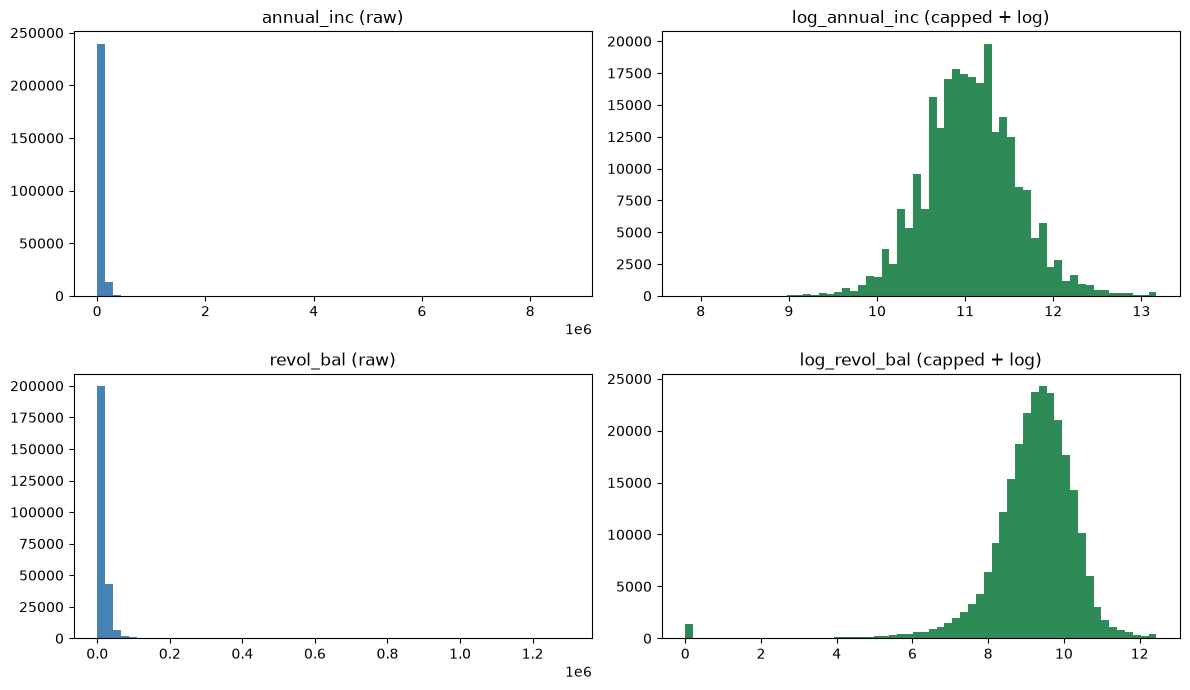

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, col in enumerate(["annual_inc", "revol_bal"]):
    axes[row, 0].hist(X_train_before[col], bins=60, color="steelblue")
    axes[row, 0].set_title(f"{col} (raw)")
    axes[row, 1].hist(X_train[f"log_{col}"], bins=60, color="seagreen")
    axes[row, 1].set_title(f"log_{col} (capped + log)")
plt.tight_layout(); plt.show()

**Before vs after:** the raw income and revolving-balance histograms are squashed against the left edge by a few huge values. After capping and the log transform, both are close to bell-shaped, which suits logistic regression and distance-based methods like SMOTE.

# 14. Dimensionality Reduction and Feature Selection

In [36]:
## 1) Highly correlated (redundant) pairs in the TRAINING data
corr_train = X_train.corr().abs()
upper = corr_train.where(np.triu(np.ones(corr_train.shape, dtype=bool), k=1))
high_pairs = upper.stack()[lambda s: s > 0.90].sort_values(ascending=False)
target_corr = X_train.corrwith(y_train).abs()

redundant = []
for (a, b), r in high_pairs.items():
    if a in redundant or b in redundant:
        continue
    weaker = a if target_corr[a] < target_corr[b] else b
    redundant.append(weaker)
    print(f"{a} vs {b}: r = {r:.3f} -> drop {weaker} "
          f"(|corr with default| {target_corr[weaker]:.3f} vs {target_corr[b if weaker == a else a]:.3f})")

X_train = X_train.drop(columns=redundant)
X_test = X_test.drop(columns=redundant)
print("\nShape after removing redundant features:", X_train.shape)

int_rate vs sub_grade_num: r = 0.974 -> drop int_rate (|corr with default| 0.248 vs 0.264)
loan_to_income vs installment_to_income: r = 0.947 -> drop installment_to_income (|corr with default| 0.129 vs 0.150)

Shape after removing redundant features: (253508, 64)


**What this does:** finds pairs of features that are almost the same thing (|r| > 0.90 on the training data). From each pair it keeps the one more correlated with default and drops the other. Keeping both adds no information and makes logistic regression coefficients unstable (multicollinearity).

**Results:** two pairs were above 0.90.
- `int_rate` and `sub_grade_num` are 0.97 correlated, because LendingClub sets the rate from the subgrade. `int_rate` is dropped and `sub_grade_num` is kept as the slightly stronger one. The rate's information still reaches the model through the three interaction features.
- `loan_to_income` and `installment_to_income` are 0.95 correlated, so `installment_to_income` is dropped.

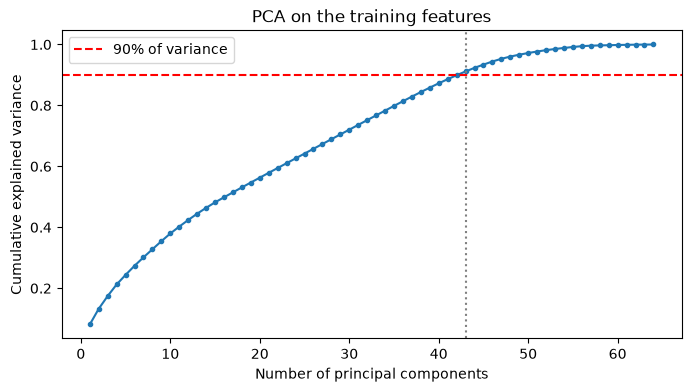

Components needed for 90% of the variance: 43 of 64 features


In [37]:
## 2) Would PCA help? Explained variance on standardized training data
X_scaled = StandardScaler().fit_transform(X_train)
pca = PCA(random_state=SEED).fit(X_scaled)
cum_var = np.cumsum(pca.explained_variance_ratio_)
n90 = np.argmax(cum_var >= 0.90) + 1

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker=".")
plt.axhline(0.90, color="red", linestyle="--", label="90% of variance")
plt.axvline(n90, color="gray", linestyle=":")
plt.xlabel("Number of principal components"); plt.ylabel("Cumulative explained variance")
plt.title("PCA on the training features"); plt.legend(); plt.show()
print(f"Components needed for 90% of the variance: {n90} of {X_train.shape[1]} features")

**What this does:** runs PCA on the standardized training features to see whether a few components capture most of the information.

**Result and decision: no PCA.** It takes 43 components to keep 90% of the variance in 64 features, so no small set of components captures most of the information. Once the near-duplicate pairs are gone, the features just aren't that redundant. PCA would also turn every feature into a blend nobody can interpret, and a lender has to be able to explain why someone was turned down. We use correlation pruning and random forest importance to cut features instead.

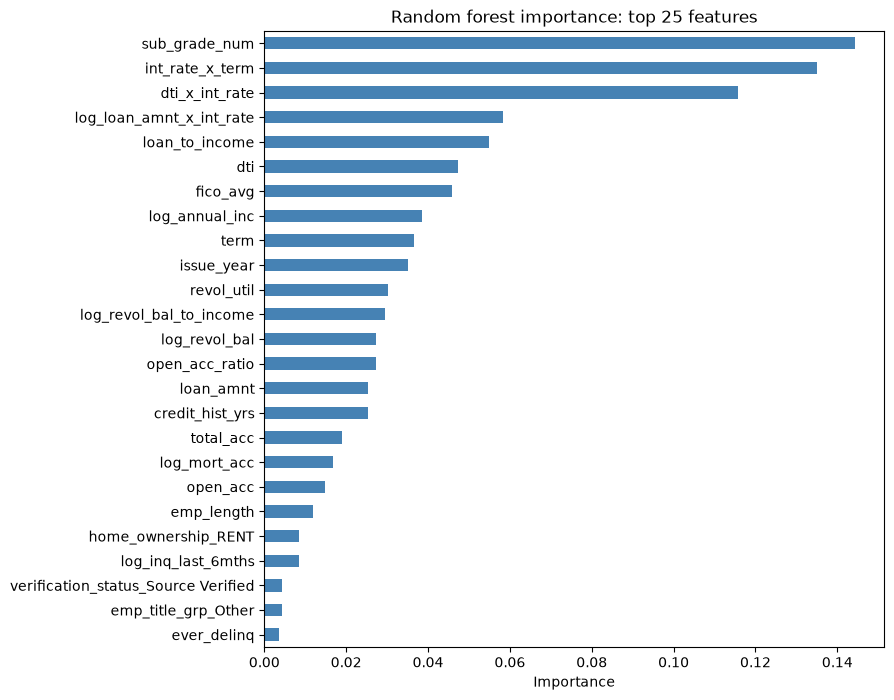

Least important features:


,Importance
log_acc_now_delinq,1.0000e-05
emp_title_grp_project manager,1.0000e-05
purpose_moving,1.0000e-05
purpose_house,1.0000e-05
emp_title_grp_office manager,1.0000e-05
emp_title_grp_director,1.0000e-05
emp_title_grp_general manager,1.0000e-05
emp_title_grp_police officer,0.0000e+00
emp_title_grp_vice president,0.0000e+00
emp_title_grp_engineer,0.0000e+00


In [38]:
## 3) Random forest feature importance (on a 60,000-loan sample of the training set, for speed)
##    If USE_ZIP is ever switched back on, zip dummies are left out of this ranking: they take ~60%
##    of the importance (Section 5 artifact) and would make every real feature look unimportant.
zip_dummies = [c for c in X_train.columns if c.startswith("zip_code_")]
X_sub = X_train.drop(columns=zip_dummies).sample(60000, random_state=SEED)
y_sub = y_train.loc[X_sub.index]
rf = RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=20,
                            class_weight="balanced", n_jobs=-1, random_state=SEED)
rf.fit(X_sub, y_sub)
importances = pd.Series(rf.feature_importances_, index=X_sub.columns).sort_values(ascending=False)

importances.head(25).sort_values().plot(kind="barh", figsize=(8, 8), color="steelblue")
plt.title("Random forest importance: top 25 features"); plt.xlabel("Importance"); plt.show()

print("Least important features:")
display(importances.tail(12).round(5).to_frame("Importance"))

In [39]:
IMPORTANCE_CUTOFF = 0.0005
low_importance = importances[importances < IMPORTANCE_CUTOFF].index.tolist()
print(f"Dropping {len(low_importance)} features with importance < {IMPORTANCE_CUTOFF}:")
print(low_importance)

X_train = X_train.drop(columns=low_importance)
X_test = X_test.drop(columns=low_importance)
print("\nFinal number of features:", X_train.shape[1])

Dropping 24 features with importance < 0.0005:
['emp_title_grp_owner', 'purpose_major_purchase', 'emp_title_grp_manager', 'emp_title_grp_teacher', 'emp_title_grp_registered nurse', 'emp_title_grp_sales', 'emp_title_grp_driver', 'purpose_medical', 'emp_title_grp_supervisor', 'emp_title_grp_truck driver', 'application_type_JOINT', 'purpose_vacation', 'log_acc_now_delinq', 'emp_title_grp_project manager', 'purpose_moving', 'purpose_house', 'emp_title_grp_office manager', 'emp_title_grp_director', 'emp_title_grp_general manager', 'emp_title_grp_police officer', 'emp_title_grp_vice president', 'emp_title_grp_engineer', 'application_type_INDIVIDUAL', 'home_ownership_OTHER']

Final number of features: 40


**What this does:** uses a random forest to rank features by how much they help predict default, then drops features that contribute almost nothing (importance < 0.0005). For grouped categoricals like `purpose` and `emp_title_grp`, this is the "use a model to select the most important categories" approach from the assignment. The forest is fit on a training sample only, so the test set plays no part in choosing features.

Zip code was already dropped (`USE_ZIP = False`). The code still leaves zip dummies out of this ranking if someone switches zip back on, because in a test run with zip it took about 60% of the total importance and pushed real features like `purpose` below the cutoff.

**Results:** the strongest predictors are `sub_grade_num`, `int_rate_x_term` and `dti_x_int_rate`, followed by `loan_amnt_x_int_rate`, `loan_to_income`, `dti`, `fico_avg` and income. Several engineered features rank near the top.

24 features fell below the cutoff and were dropped:
- 15 of the 16 job-title dummies. Only `emp_title_grp_Other` survives, so the model now just knows whether the title was uncommon (1) or one of the top 15 / missing (0).
- 5 rare `purpose` levels (`major_purchase`, `medical`, `vacation`, `moving`, `house`). `credit_card`, `debt_consolidation`, `home_improvement`, `small_business` and `other` stay.
- Both `application_type` dummies, `home_ownership_OTHER` and `log_acc_now_delinq`.

That leaves **40 features**.

# 15. Addressing Class Imbalance with SMOTE

,Original train,SMOTE train (X_train_O)
default,,
Fully Paid (0),203766,203766
Charged Off (1),49742,203766


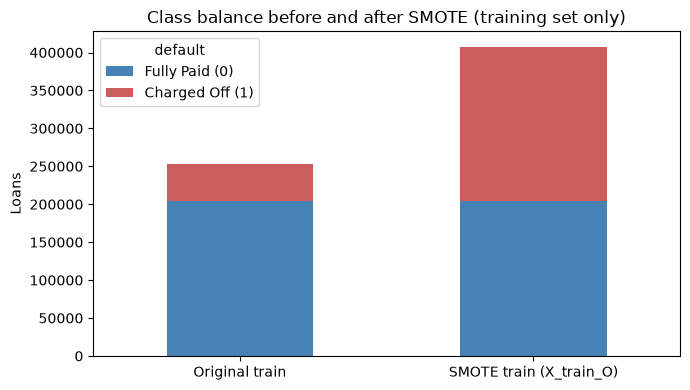

In [40]:
smote = SMOTE(random_state=SEED)
X_train_O, y_train_O = smote.fit_resample(X_train, y_train)

## SMOTE blends neighbors, so 0/1 columns come out as fractions -> round them back to 0/1
binary_final = [c for c in X_train.columns if X_train[c].nunique() <= 2]
X_train_O[binary_final] = X_train_O[binary_final].round().astype(int)

counts = pd.DataFrame({"Original train": y_train.value_counts(),
                       "SMOTE train (X_train_O)": y_train_O.value_counts()})
counts.index = counts.index.map({0: "Fully Paid (0)", 1: "Charged Off (1)"})
display(counts)

counts.T.plot(kind="bar", stacked=True, figsize=(7, 4), color=["steelblue", "indianred"])
plt.title("Class balance before and after SMOTE (training set only)")
plt.ylabel("Loans"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**What this does:** applies SMOTE (Synthetic Minority Oversampling Technique) to the **training set only**. SMOTE creates new synthetic defaults by interpolating between a real default and one of its nearest default neighbors, until both classes are the same size. The test set is untouched, so it still reflects the real ~4:1 mix the model will face.

SMOTE works with numeric distances, so it ran *after* imputation, capping and log transforms. Because it blends two loans, dummy columns come out as fractions like 0.37; those are rounded back to 0/1 so every synthetic loan has valid categories.

In the modeling phase we'll train each model on both `X_train` and `X_train_O` and keep whichever does better on the test set.

**Results:** the training set goes from 203,766 paid vs 49,742 defaults to 203,766 of each (407,532 rows). The test set is unchanged: 63,377 loans, 19.6% defaults.

# 16. Saving the Final Data Sets

In [ ]:
## Full training/test sets for the modeling phase
X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)
X_train_O.to_csv("X_train_O.csv", index=False)
y_train_O.to_csv("y_train_O.csv", index=False)

## Final data set = processed train + test with the target
df_final = pd.concat([pd.concat([X_train, y_train], axis=1),
                      pd.concat([X_test, y_test], axis=1)])

## Deliverable samples (n = 1000)
df_sample = df_final.sample(1000, random_state=SEED)
df_sample.to_csv("group_20.csv", index=False)
X_train.sample(1000, random_state=SEED).to_csv("X_train_sample.csv", index=False)
X_train_O.sample(1000, random_state=SEED).to_csv("X_train_O_sample.csv", index=False)

print("df_final:", df_final.shape, "  X_train:", X_train.shape, "  X_test:", X_test.shape,
      "  X_train_O:", X_train_O.shape)
df_sample.head()

df_final: (316885, 41)   X_train: (253508, 40)   X_test: (63377, 40)   X_train_O: (407532, 40)


,loan_amnt,term,emp_length,log_annual_inc,dti,open_acc,log_pub_rec,log_revol_bal,revol_util,total_acc,log_mort_acc,log_pub_rec_bankruptcies,log_delinq_2yrs,log_inq_last_6mths,loan_to_income,log_revol_bal_to_income,open_acc_ratio,fico_avg,sub_grade_num,credit_hist_yrs,issue_year,int_rate_x_term,log_loan_amnt_x_int_rate,dti_x_int_rate,ever_delinq,home_ownership_OWN,home_ownership_RENT,verification_status_Source Verified,verification_status_Verified,purpose_credit_card,purpose_debt_consolidation,purpose_home_improvement,purpose_other,purpose_small_business,initial_list_status_w,emp_title_grp_Other,loan_size_medium,loan_size_large,emp_length_missing,mort_acc_missing,default
275068,4500.0,36,2.0,10.5454,34.78,24.0,0.0000,7.9603,11.2,29.0,0.0000,0.0000,0.0000,1.3863,0.1184,0.0727,0.8276,737.0,12,5.6646,2015,38.07,6.3492,441.3582,1,0,1,0,0,0,1,0,0,0,1,1,0,0,0,0,0
61119,9000.0,36,5.0,11.0021,10.90,7.0,0.0000,9.0485,68.0,18.0,0.0000,0.0000,0.0000,0.0000,0.1500,0.1326,0.3889,667.0,11,12.2437,2014,40.95,7.1144,148.7850,1,0,1,1,0,0,1,0,0,0,1,1,0,0,0,0,0
153333,11200.0,36,1.0,10.4344,4.22,6.0,0.0000,7.9838,8.4,7.0,0.0000,0.0000,0.6931,0.6931,0.3293,0.0827,0.8571,682.0,7,24.0821,2015,27.51,6.9354,38.6974,1,0,1,0,1,0,0,0,0,0,1,1,1,0,0,0,0
51576,10500.0,36,2.0,11.2898,15.65,15.0,0.0000,8.8863,67.6,37.0,0.6931,0.0000,0.0000,0.0000,0.1313,0.0865,0.4054,697.0,9,25.4182,2015,32.97,7.0518,171.9935,1,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0
271770,12500.0,36,10.0,10.3418,31.71,8.0,0.6931,9.1459,53.9,23.0,1.0986,0.6931,0.6931,0.6931,0.4032,0.2642,0.3478,662.0,11,19.3292,2014,40.95,7.4426,432.8415,1,1,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0


**What this does:** saves everything the modeling phase needs, plus the three deliverable samples.

| File | Contents |
|---|---|
| `X_train.csv`, `y_train.csv` | Processed training set (80%) |
| `X_test.csv`, `y_test.csv` | Processed test set (20%), never resampled |
| `X_train_O.csv`, `y_train_O.csv` | SMOTE-oversampled training set |
| `group_1.csv` | **Deliverable:** 1,000-row sample of the final data set (features + `default`) |
| `X_train_sample.csv` | **Deliverable:** 1,000-row sample of `X_train` |
| `X_train_O_sample.csv` | **Deliverable:** 1,000-row sample of `X_train_O` |

Rename `group_1.csv` to match our group number before submitting.

# 17. Summary and Notes for the Modeling Phase

**Final data set:** 316,885 loans, 40 features plus the target `default` (1 = Charged Off). 80/20 stratified split with seed 591; SMOTE applied to the training set only.

**Zip code was dropped** (`USE_ZIP = False`, Section 5). Every zip code appears in all 54 states, and six of the ten are exactly 0% or 100% default, so the zip codes were evidently assigned from the outcome rather than from real locations. Keeping zip would have inflated test scores without helping on real applicants. This is worth calling out in the write-up.

**For the modeling phase:**
- Logistic regression and KNN need scaled features. Fit a `StandardScaler` on `X_train` (or `X_train_O`) only, then apply it to `X_test`. Tree-based models don't need scaling.
- Don't judge models on accuracy. Predicting "paid" for everyone already scores 80%. Use AUC, recall, precision and F1 on the default class.
- Train each model on both `X_train` and `X_train_O` and keep whichever does better on `X_test`.
- `issue_year` reflects economic conditions when the loan was issued. It's useful here, but a lender scoring brand-new applicants would be extrapolating past 2016.